# EDA: Player Salaries & Team Payroll (Basketball-Reference via llimllib)

This notebook is the EDA for our salary data, which comes from llimllib/nba_data, a public GitHub repo that collects Basketball-Reference's salary data into downloadable files. We picked it because it has every player on every team's payroll for all the seasons we need (2015-16 to 2025-26) in one consistent format, so we don't have to scrape Basketball-Reference ourselves. Since it covers whole rosters, we can also add up each team's total payroll, not just look at individual salaries. The cleaning is done in `New-Cleaning/salary-data/02-llimllib-Salaries-Payroll.ipynb`, and this notebook only loads its two outputs:

- `llimllib_player_salary_features.csv`: one row per player + season + team
- `llimllib_team_payroll_features.csv`: one row per team + season

Both are copied into `data/` in this folder so the notebook runs on its own. We also copy `offseason_traded_players.csv` (from the NBA.com transactions data) so we can compare salary to our outcome, whether a player gets traded in the offseason.

**Main question for this EDA:** does how much a player is paid, or how expensive his team's payroll is, look related to him being traded in the next offseason?

## 1. Load the data and add the trade label

The salary tables use the **end** year for `season` (2016 = 2015-16). The trades file uses `offseason_after_season`, which is the **start** year of the season that just ended (2015 = the summer after 2015-16). So to match them we add 1 to `offseason_after_season`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

players = pd.read_csv('data/llimllib_player_salary_features.csv')
payroll = pd.read_csv('data/llimllib_team_payroll_features.csv')
trades = pd.read_csv('data/offseason_traded_players.csv')

print('players:', players.shape)
print('payroll:', payroll.shape)
print('trades:', trades.shape)

players: (6767, 24)
payroll: (330, 22)
trades: (555, 10)


In [2]:
# one row per traded player per offseason, with season switched to the end year
traded = trades[['offseason_after_season', 'player_id']].drop_duplicates().copy()
traded['season'] = traded['offseason_after_season'] + 1
traded['traded_next_offseason'] = True

eda = players.merge(traded[['season', 'player_id', 'traded_next_offseason']],
                    left_on=['season', 'nba_player_id'], right_on=['season', 'player_id'],
                    how='left').drop(columns='player_id')
eda['traded_next_offseason'] = eda['traded_next_offseason'].fillna(False).astype(bool)

# a player waived mid-season can be paid by 2 teams in the same season (2 rows).
# for player-level questions we keep the row with his biggest salary
print('player-seasons with 2+ rows:', eda.duplicated(['season', 'nba_player_id']).sum())
eda = (eda.sort_values('cap_salary', ascending=False)
          .drop_duplicates(['season', 'nba_player_id'])
          .reset_index(drop=True))

base_rate = eda['traded_next_offseason'].mean() * 100
print('player-seasons:', len(eda))
print(f"traded next offseason: {eda['traded_next_offseason'].sum()} ({base_rate:.1f}%)")

player-seasons with 2+ rows: 553
player-seasons: 6214
traded next offseason: 520 (8.4%)


**Note:** The trades file starts with the summer 2015 offseason (`offseason_after_season` = 2014), which has no salary season to match, so those 30 trades aren't used. Of the 525 traded player-offseasons from 2015-16 on, 520 match a salary row (99%). After keeping one row per player-season, 8.4% of player-seasons are traded in the next offseason, so the classes are very unbalanced.

## 2. How are salaries distributed?

We use `salary_pct_of_cap` (salary as a % of that season's salary cap) instead of raw dollars, because the cap went from $70M in 2015-16 to about $155M in 2025-26, so the same dollar amount means different things in different seasons.

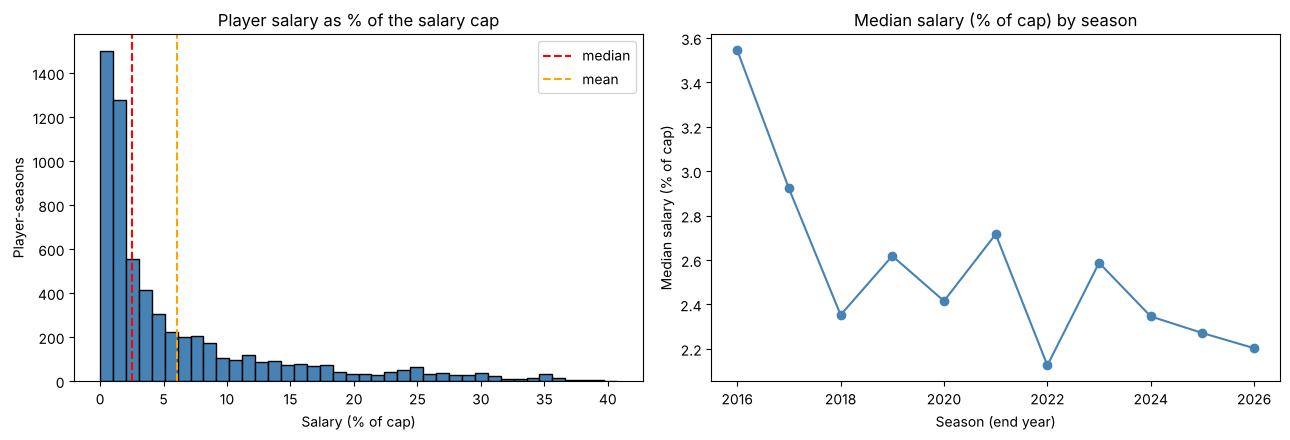

count    6214.00
mean        6.08
std         7.92
min         0.00
25%         1.19
50%         2.49
75%         8.08
max        40.73
Name: salary_pct_of_cap, dtype: float64
skew: 1.86
two-way contracts: 9.3% of player-seasons


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(eda['salary_pct_of_cap'], bins=40, color='steelblue', edgecolor='black')
axes[0].axvline(eda['salary_pct_of_cap'].median(), color='red', linestyle='--', label='median')
axes[0].axvline(eda['salary_pct_of_cap'].mean(), color='orange', linestyle='--', label='mean')
axes[0].set_title('Player salary as % of the salary cap')
axes[0].set_xlabel('Salary (% of cap)')
axes[0].set_ylabel('Player-seasons')
axes[0].legend()

med_by_season = eda.groupby('season')['salary_pct_of_cap'].median()
axes[1].plot(med_by_season.index, med_by_season.values, marker='o', color='steelblue')
axes[1].set_title('Median salary (% of cap) by season')
axes[1].set_xlabel('Season (end year)')
axes[1].set_ylabel('Median salary (% of cap)')

plt.tight_layout()
plt.show()

print(eda['salary_pct_of_cap'].describe().round(2))
print('skew:', round(eda['salary_pct_of_cap'].skew(), 2))
print(f"two-way contracts: {eda['is_two_way'].mean() * 100:.1f}% of player-seasons")

### What we found

* **Very right-skewed:** most players make a small share of the cap and a few stars make a lot. The median is 2.5% of the cap but the mean is 6.1%, and the skew is 1.86. So we should use medians (not means) when we summarize salary, and Spearman (not Pearson) for correlations.
* **Top end:** the highest is Stephen Curry in 2021-22 at 40.7% of the cap. 319 player-seasons are at 25% or more, which is basically max-contract territory.
* **Two-way contracts:** 9.3% of player-seasons are two-way deals, which pay almost nothing and make up a big part of the bottom bin.
* **Over time:** the median goes from 3.6% in 2015-16 to about 2.1-2.7% after that. Rosters got bigger (more two-way and minimum players), so the typical player takes a smaller share of the cap.

## 3. Are higher-paid players traded more often?

We split players into salary groups (as % of cap) and look at the % traded in the next offseason in each group. The error bars are a rough 95% interval (±1.96 standard errors), and the dashed line is the rate for all players.

In [4]:
bins = [-0.01, 2, 5, 10, 20, 100]
labels = ['under 2%', '2-5%', '5-10%', '10-20%', '20%+']
eda['salary_group'] = pd.cut(eda['salary_pct_of_cap'], bins=bins, labels=labels)

salary_table = eda.groupby('salary_group', observed=True)['traded_next_offseason'].agg(['count', 'sum', 'mean'])
salary_table.columns = ['players', 'traded', 'trade_rate']
salary_table['trade_rate'] = salary_table['trade_rate'] * 100
salary_table['ci95'] = 1.96 * np.sqrt(salary_table['trade_rate'] * (100 - salary_table['trade_rate']) / salary_table['players'])
salary_table.round(1)

,players,traded,trade_rate,ci95
salary_group,,,,
under 2%,2760,122,4.4,0.8
2-5%,1266,111,8.8,1.6
5-10%,917,108,11.8,2.1
10-20%,763,117,15.3,2.6
20%+,508,62,12.2,2.8


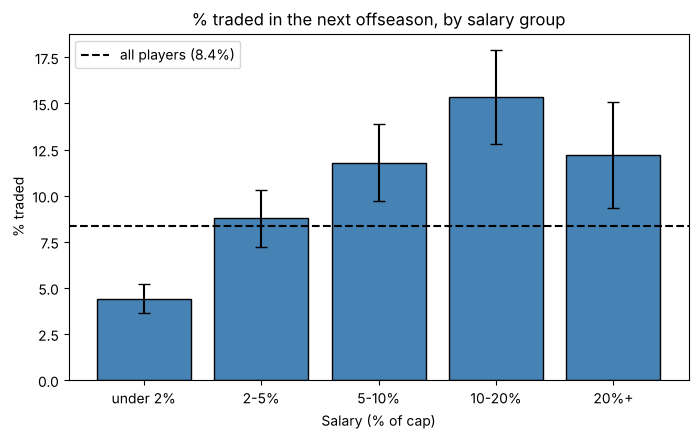

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(salary_table.index.astype(str), salary_table['trade_rate'], yerr=salary_table['ci95'],
       color='steelblue', edgecolor='black', capsize=4)
ax.axhline(base_rate, color='black', linestyle='--', label=f'all players ({base_rate:.1f}%)')
ax.set_title('% traded in the next offseason, by salary group')
ax.set_xlabel('Salary (% of cap)')
ax.set_ylabel('% traded')
ax.legend()
plt.show()

### What we found

* **Trade rate goes up with salary until the top group:** 4.4% for players under 2% of the cap, then 8.8%, 11.8%, and 15.3% for the 10-20% group (the highest). The top group (20%+) drops back to 12.2%.
* **Why the bottom is so low:** two-way players are almost never traded (0.7%, 579 player-seasons), and they make up a lot of the under-2% group. Even without them, cheap players are traded less (5.4%).
* **Why mid-salary is the highest:** our guess is that teams need salary to match in trades, so mid-size contracts are the easiest to move, while stars are less often traded. This is only a pattern though, not a cause.
* The error bars for the middle groups don't overlap the bottom group, so the difference doesn't look like random noise.

## 4. Team payroll

Next we look at the team side. `payroll_pct_of_cap` is the team's total payroll as a % of the cap, and `tax_tier` says which line the team is over (0 = under the cap, 1 = over the cap, 2 = over the luxury tax, 3 = over the first apron, 4 = over the second apron). The second apron only exists from 2023-24 on.

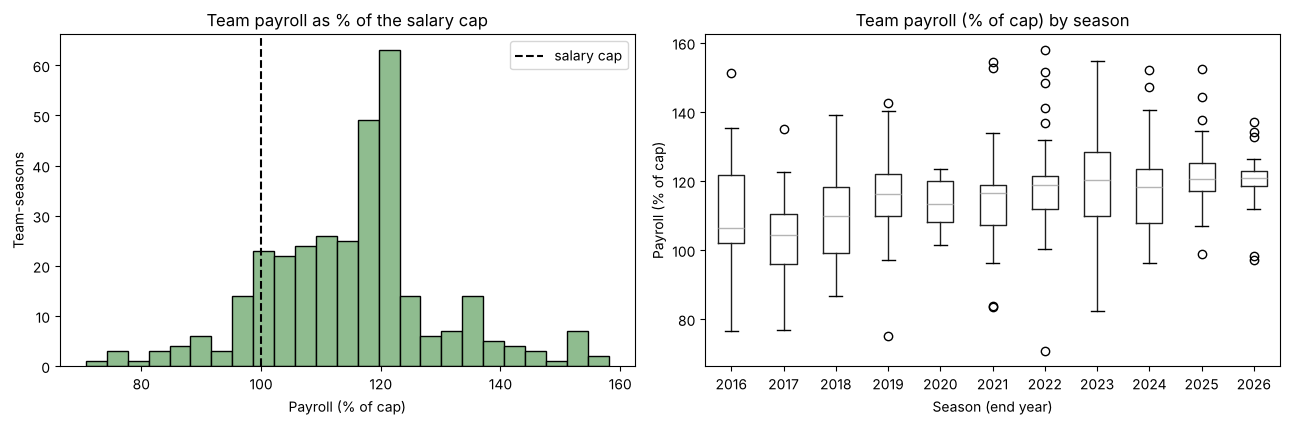

count    330.0
mean     115.3
std       14.5
min       70.7
25%      106.4
50%      117.1
75%      121.3
max      158.1
Name: payroll_pct_of_cap, dtype: float64
tax_tier
0     43
1    208
2     31
3     40
4      8
Name: count, dtype: int64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(payroll['payroll_pct_of_cap'], bins=25, color='darkseagreen', edgecolor='black')
axes[0].axvline(100, color='black', linestyle='--', label='salary cap')
axes[0].set_title('Team payroll as % of the salary cap')
axes[0].set_xlabel('Payroll (% of cap)')
axes[0].set_ylabel('Team-seasons')
axes[0].legend()

payroll.boxplot(column='payroll_pct_of_cap', by='season', ax=axes[1], grid=False)
axes[1].set_title('Team payroll (% of cap) by season')
axes[1].set_xlabel('Season (end year)')
axes[1].set_ylabel('Payroll (% of cap)')
fig.suptitle('')

plt.tight_layout()
plt.show()

print(payroll['payroll_pct_of_cap'].describe().round(1))
print(payroll['tax_tier'].value_counts().sort_index())

### What we found

* **Almost every team is over the cap:** only 13% of team-seasons are under 100% of the cap. The median payroll is 117% of the cap, and most teams are between 106% and 121%.
* **Payrolls keep rising compared to the cap:** the median goes from 106% in 2015-16 to about 120% in the last three seasons.
* **Extremes:** the highest is Golden State in 2021-22 (158% of the cap) and the lowest is Oklahoma City in 2021-22 (71%).
* **Tax tiers:** most team-seasons are in tier 1 (over the cap but under the tax, 208 of 330). Tier 4 (over the second apron) only shows up 8 times because it only exists from 2023-24.

Now we check if players on more expensive teams get traded more. Each player-season already has his team's `tax_tier`, so we group by it.

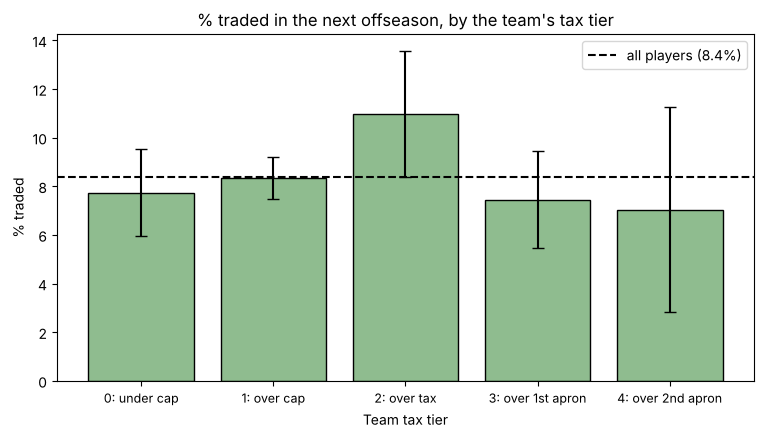

,players,traded,trade_rate,ci95
tax_tier_name,,,,
0: under cap,866,67,7.7,1.8
1: over cap,3979,332,8.3,0.9
2: over tax,556,61,11.0,2.6
3: over 1st apron,671,50,7.5,2.0
4: over 2nd apron,142,10,7.0,4.2


In [7]:
tier_names = {0: '0: under cap', 1: '1: over cap', 2: '2: over tax', 3: '3: over 1st apron', 4: '4: over 2nd apron'}
eda['tax_tier_name'] = eda['tax_tier'].map(tier_names)

tier_table = eda.groupby('tax_tier_name')['traded_next_offseason'].agg(['count', 'sum', 'mean'])
tier_table.columns = ['players', 'traded', 'trade_rate']
tier_table['trade_rate'] = tier_table['trade_rate'] * 100
tier_table['ci95'] = 1.96 * np.sqrt(tier_table['trade_rate'] * (100 - tier_table['trade_rate']) / tier_table['players'])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(tier_table.index, tier_table['trade_rate'], yerr=tier_table['ci95'],
       color='darkseagreen', edgecolor='black', capsize=4)
ax.axhline(base_rate, color='black', linestyle='--', label=f'all players ({base_rate:.1f}%)')
ax.set_title("% traded in the next offseason, by the team's tax tier")
ax.set_xlabel('Team tax tier')
ax.set_ylabel('% traded')
ax.tick_params(axis='x', labelsize=9)
ax.legend()
plt.show()

tier_table.round(1)

### What we found

* **No clear pattern by tier:** the rates are 7.7% (under cap), 8.3% (over cap), 11.0% (over tax), 7.5% (over 1st apron) and 7.0% (over 2nd apron). Only the "over tax" group is a bit higher.
* **Small groups:** tier 4 only has 142 player-seasons, so its error bar is very wide (±4.2 points) and we can't say much about it.
* So the team's payroll level alone doesn't look like a strong signal. It might still matter when combined with other features (like the player's own salary), which is something to try in the model.

## 5. Correlations with the trade label

Last, a quick check of how each llimllib feature relates to `traded_next_offseason`. We use Spearman correlation because salary is very skewed and `tax_tier` is ordered categories, not a regular number.

In [8]:
corr_cols = ['salary_pct_of_cap', 'cap_salary', 'payroll_pct_of_cap', 'tax_tier', 'dollars_vs_tax_pct_cap', 'is_two_way']
corr = eda[corr_cols + ['traded_next_offseason']].astype(float).corr(method='spearman')['traded_next_offseason'].drop('traded_next_offseason')
corr.sort_values().round(3)

is_two_way               -0.089
tax_tier                  0.008
dollars_vs_tax_pct_cap    0.022
payroll_pct_of_cap        0.022
salary_pct_of_cap         0.152
cap_salary                0.152
Name: traded_next_offseason, dtype: float64

### What we found

* **Salary has the strongest link:** `salary_pct_of_cap` and `cap_salary` both have a Spearman correlation of 0.15 with being traded. They are almost the same feature, so we should only use one in the model (we'd pick `salary_pct_of_cap` since it adjusts for the cap).
* **Two-way flag is negative (-0.09):** two-way players are less likely to be traded, which matches section 3.
* **Team payroll features are close to 0** (0.01-0.02), which matches the flat tax-tier chart.
* All of these are weak on their own, which makes sense since a trade depends on a lot of things (performance, contract years left, team situation).

## 6. Summary

* The llimllib table has 6,214 player-seasons (2015-16 to 2025-26) after keeping one row per player-season, and 8.4% of them are traded in the next offseason.
* Salary as a % of the cap is very right-skewed (median 2.5%, mean 6.1%), so medians and Spearman correlations make more sense than means and Pearson.
* **Player salary is the most useful llimllib feature.** Trade rate rises from 4.4% for the cheapest players to 15.3% for players making 10-20% of the cap, then dips for the highest-paid players.
* **Team payroll and tax tier show little difference on their own** (all tiers between 7% and 11%), but they could still help combined with other features.
* Two-way contracts are almost never traded, so `is_two_way` is worth keeping.
* `cap_salary` and `salary_pct_of_cap` carry the same information, so only one should go into the model.